# PE Mask Comparison: JSON-derived vs MATLAB-equivalent computed

This notebook compares two ways of building the equispaced PE sampling mask:

1. **JSON-derived mask** — using `_build_pe_mask_from_json` logic from `equispaced_recon.py`  
   (reads `Undersampled4equispaces.json`, converts physical ky → PE index)

2. **MATLAB-equivalent computed mask** — Python re-implementation of `generate_equispaced_1D`  
   from `kband_se_t1.m` (pure arithmetic, no JSON)

The goal is to verify that both masks select the same PE lines.

In [11]:
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── Adjust path so we can call the app's load_trajectory directly ──────────
APP_ROOT = Path("../").resolve()   # AnalyzeMRIDataApp/
if str(APP_ROOT) not in sys.path:
    sys.path.insert(0, str(APP_ROOT))

print("App root:", APP_ROOT)

App root: C:\Users\saard\OneDrive - Technion\תואר שני\MRI_Acquisition_Reconstruction_Toolkit\AnalyzeMRIDataApp


## 1 — Configuration

Edit the variables below to match the parameters used when you ran `generate_equispaced_1D` in MATLAB.

In [12]:
# ── MATLAB parameters (must match the values used when the JSON was generated) ──
READOUT_LENGTH = 256   # readout_length
R_FACTOR       = 4     # R_factor
ACS_LINES      = 24    # acs_lines

# ── Path to the JSON trajectory file ─────────────────────────────────────────
JSON_PATH = Path(
    r"..\..\scans\SE_1mm\Undersampled4equispaces.json"
).resolve()

print("JSON file:", JSON_PATH)
print("Exists   :", JSON_PATH.exists())

JSON file: C:\Users\saard\OneDrive - Technion\תואר שני\MRI_Acquisition_Reconstruction_Toolkit\scans\SE_1mm\Undersampled4equispaces.json
Exists   : True


## 2 — Build mask from JSON  
### (`_build_pe_mask_from_json` logic — analytical approach)

**Why a direct ky → PE-index conversion fails:**  
The MATLAB script applies a continuous k-space centering shift (`initial_kshift = -center`) before  
writing the JSON.  This shifts all ky values by a non-integer multiple of delta_ky, causing  
*different integer offsets* for the equispaced lines (+2) vs the ACS boundary (−1) after rounding —  
so a simple global shift cannot reconcile the two masks.

**Fix:** use the JSON only to *detect* R and ACS_lines, then rebuild the mask analytically using  
the same arithmetic as MATLAB (`center = n_phase // 2`, equispaced at `center ± k*R`, ACS at  
`center ± acs_lines//2`).  The centering offset is eliminated entirely.


In [13]:
# ── Inline the load_trajectory helper (avoids package import issues) ──────────
def load_trajectory_local(json_path: str, idx: str = "0") -> np.ndarray:
    """Load kx/ky trajectory from JSON.  Returns (N_samples, 2)."""
    with open(json_path, "r") as f:
        all_data = json.load(f)
    traj_list = all_data[str(idx)]
    traj_np = np.array(traj_list).T   # (N_samples, coord_dim)
    return traj_np[:, :2]             # kx, ky only


def build_pe_mask_from_json(json_path: str, n_phase: int):
    """
    Derive a boolean PE mask that exactly matches MATLAB generate_equispaced_1D.

    Strategy
    --------
    The MATLAB sequence applies a continuous k-space centering shift before
    saving the JSON, causing a mixed integer offset (different for equispaced
    vs ACS boundary lines) that a simple global shift cannot fix.

    Instead we:
      1. Compute delta_ky = minimum positive ky spacing (= 1/FOV).
      2. First-pass ky → PE-index conversion to get raw indices (with offset).
      3. Detect R = median of large PE-index steps (equispaced step = R).
      4. Detect ACS_lines = length of the longest consecutive step-1 run.
      5. Rebuild the mask ANALYTICALLY using MATLAB-equivalent arithmetic:
             center = n_phase // 2
             equispaced : center ± k*R   (k = 0, 1, 2, …)
             ACS        : center ± acs_lines//2
         This removes the centering offset and gives an exact MATLAB match.

    Returns
    -------
    mask             : bool array shape (n_phase,)
    pe_indices       : int array of acquired PE indices (0-based)
    delta_ky         : float — smallest ky step (1/m)
    R_detected       : int   — detected acceleration factor
    acs_lines_detect : int   — detected ACS line count
    """
    traj    = load_trajectory_local(str(json_path))   # (N_samples, 2)
    ky_vals = traj[:, 1]

    unique_ky = np.unique(ky_vals)
    ky_diffs  = np.diff(unique_ky)
    pos_diffs = ky_diffs[ky_diffs > 1e-9]
    assert pos_diffs.size > 0, "Could not determine delta_ky: no positive ky steps found."
    delta_ky = float(np.min(pos_diffs))

    # --- First-pass raw PE indices (may carry centering offset) ---
    pe_float = unique_ky / delta_ky + (n_phase / 2)
    pe_raw   = np.unique(np.clip(np.round(pe_float).astype(int), 0, n_phase - 1))

    # --- Detect R from large steps ---
    pe_steps    = np.diff(pe_raw)
    large_steps = pe_steps[pe_steps > 1]
    assert large_steps.size > 0, "Could not detect R: no step > 1 found."
    R_detected = int(np.round(np.median(large_steps)))

    # --- Detect ACS lines from longest consecutive step-1 run ---
    step1_idx = np.where(pe_steps == 1)[0]
    if step1_idx.size > 0:
        groups = np.split(step1_idx, np.where(np.diff(step1_idx) > 1)[0] + 1)
        acs_lines_detected = len(max(groups, key=len))
    else:
        acs_lines_detected = 0

    print(f"  Detected from JSON : R={R_detected}, ACS_lines={acs_lines_detected}, delta_ky={delta_ky:.4f} 1/m")

    # --- Analytical mask (MATLAB-equivalent) ---
    center_idx = n_phase // 2
    mask = np.zeros(n_phase, dtype=bool)
    mask[np.arange(center_idx, n_phase, R_detected)] = True
    mask[np.arange(center_idx, -1,      -R_detected)] = True

    acs_h_lo   = acs_lines_detected // 2
    acs_h_hi   = acs_lines_detected - acs_h_lo
    acs_start_a = max(0, center_idx - acs_h_lo)
    acs_end_a   = min(n_phase, center_idx + acs_h_hi)
    mask[acs_start_a:acs_end_a] = True

    pe_indices = np.where(mask)[0]
    return mask, pe_indices, delta_ky, R_detected, acs_lines_detected


json_mask, json_pe_idx, delta_ky, R_detected, acs_detected = build_pe_mask_from_json(
    JSON_PATH, READOUT_LENGTH
)

print(f"delta_ky           : {delta_ky:.6f}  1/m")
print(f"R detected         : {R_detected}")
print(f"ACS lines detected : {acs_detected}")
print(f"JSON mask lines    : {json_mask.sum()} / {READOUT_LENGTH}")
print(f"First 10 PE indices: {json_pe_idx[:10].tolist()}")
print(f"Last  10 PE indices: {json_pe_idx[-10:].tolist()}")


  Detected from JSON : R=4, ACS_lines=24, delta_ky=3.9062 1/m
delta_ky           : 3.906250  1/m
R detected         : 4
ACS lines detected : 24
JSON mask lines    : 82 / 256
First 10 PE indices: [0, 4, 8, 12, 16, 20, 24, 28, 32, 36]
Last  10 PE indices: [216, 220, 224, 228, 232, 236, 240, 244, 248, 252]


In [14]:
# ── For reference: show the RAW pe_indices (direct ky→index, before correction) ─
traj_ref  = load_trajectory_local(str(JSON_PATH))
ky_ref    = traj_ref[:, 1]
unique_ky_ref = np.unique(ky_ref)
pos_diffs_ref = np.diff(unique_ky_ref)
pos_diffs_ref = pos_diffs_ref[pos_diffs_ref > 1e-9]
delta_ky_ref  = float(np.min(pos_diffs_ref))

pe_raw_ref = np.unique(np.clip(
    np.round(unique_ky_ref / delta_ky_ref + READOUT_LENGTH / 2).astype(int),
    0, READOUT_LENGTH - 1
))

print("Raw PE indices (direct ky→index, carries centering offset):")
print(f"  First 10 : {pe_raw_ref[:10].tolist()}  ← shifted +2 from MATLAB")
print()
print("Corrected PE indices (analytical rebuild, centering offset removed):")
print(f"  First 10 : {json_pe_idx[:10].tolist()}  ← should match MATLAB exactly")


Raw PE indices (direct ky→index, carries centering offset):
  First 10 : [2, 6, 10, 14, 18, 22, 26, 30, 34, 38]  ← shifted +2 from MATLAB

Corrected PE indices (analytical rebuild, centering offset removed):
  First 10 : [0, 4, 8, 12, 16, 20, 24, 28, 32, 36]  ← should match MATLAB exactly


## 3 — Build mask using MATLAB-equivalent arithmetic

Python translation of `generate_equispaced_1D` from `kband_se_t1.m`.  
MATLAB is 1-indexed; we convert everything to 0-indexed Python.

In [15]:
def build_pe_mask_matlab_equiv(readout_length: int, R_factor: int, acs_lines: int):
    """
    Python equivalent of the MATLAB generate_equispaced_1D mask.

    MATLAB (1-indexed):
        center_idx = floor(readout_length/2) + 1       % e.g. 129 for 256
        idx_right  = center_idx : R_factor : readout_length
        idx_left   = center_idx : -R_factor : 1
        acs_start  = center_idx - floor(acs_lines/2)
        acs_end    = center_idx + ceil(acs_lines/2) - 1
        pe_mask(acs_start:acs_end) = true

    Converted to Python (0-indexed):
        center_idx = readout_length // 2               % 128 for 256
        idx_right  = range(center_idx, readout_length, R_factor)
        idx_left   = range(center_idx, -1, -R_factor)
        acs_start  = center_idx - acs_lines // 2       % 116 for acs=24
        acs_end    = center_idx + (acs_lines - acs_lines//2)  % 140 exclusive
    """
    pe_mask    = np.zeros(readout_length, dtype=bool)
    center_idx = readout_length // 2   # 0-indexed centre (MATLAB center_idx - 1)

    # Equispaced lines anchored to center
    idx_right = np.arange(center_idx, readout_length, R_factor)
    idx_left  = np.arange(center_idx, -1, -R_factor)
    pe_mask[idx_right] = True
    pe_mask[idx_left]  = True

    # Fully sampled ACS centre
    acs_half_lo = acs_lines // 2          # floor(acs_lines/2)
    acs_half_hi = acs_lines - acs_half_lo # ceil(acs_lines/2)
    acs_start = center_idx - acs_half_lo  # inclusive, 0-indexed
    acs_end   = center_idx + acs_half_hi  # exclusive (Python slice)
    pe_mask[acs_start:acs_end] = True

    pe_indices = np.where(pe_mask)[0]
    return pe_mask, pe_indices, acs_start, acs_end


matlab_mask, matlab_pe_idx, acs_start, acs_end = build_pe_mask_matlab_equiv(
    READOUT_LENGTH, R_FACTOR, ACS_LINES
)

print(f"MATLAB mask lines   : {matlab_mask.sum()} / {READOUT_LENGTH}")
print(f"First 10 PE indices : {matlab_pe_idx[:10].tolist()}")
print(f"Last  10 PE indices : {matlab_pe_idx[-10:].tolist()}")
print(f"ACS region (0-idx)  : [{acs_start}, {acs_end})  ({acs_end - acs_start} lines)")

MATLAB mask lines   : 82 / 256
First 10 PE indices : [0, 4, 8, 12, 16, 20, 24, 28, 32, 36]
Last  10 PE indices : [216, 220, 224, 228, 232, 236, 240, 244, 248, 252]
ACS region (0-idx)  : [116, 140)  (24 lines)


## 4 — Numerical comparison

In [16]:
# ── Set operations ────────────────────────────────────────────────────────────
json_set   = set(json_pe_idx.tolist())
matlab_set = set(matlab_pe_idx.tolist())

only_in_json   = sorted(json_set   - matlab_set)
only_in_matlab = sorted(matlab_set - json_set)
in_both        = sorted(json_set   & matlab_set)

total_json   = len(json_set)
total_matlab = len(matlab_set)
total_common = len(in_both)

print("=" * 60)
print(f"  JSON-derived lines   : {total_json}")
print(f"  MATLAB-equiv lines   : {total_matlab}")
print(f"  Lines in BOTH        : {total_common}")
print(f"  Only in JSON         : {len(only_in_json)}  →  {only_in_json}")
print(f"  Only in MATLAB       : {len(only_in_matlab)}  →  {only_in_matlab}")
print("=" * 60)

if only_in_json == [] and only_in_matlab == []:
    print("✅  Masks are IDENTICAL.")
elif len(only_in_json) == len(only_in_matlab):
    offsets = [j - m for j, m in zip(sorted(only_in_json), sorted(only_in_matlab))]
    if len(set(offsets)) == 1:
        print(f"⚠️  Masks are SHIFTED by {offsets[0]:+d} PE lines " 
              f"(k-space centering offset expected).")
    else:
        print(f"⚠️  Masks differ (non-uniform shift).")
else:
    print("❌  Masks differ in both count and positions.")

  JSON-derived lines   : 82
  MATLAB-equiv lines   : 82
  Lines in BOTH        : 82
  Only in JSON         : 0  →  []
  Only in MATLAB       : 0  →  []
✅  Masks are IDENTICAL.


## 5 — Check for a constant offset between the two masks

The MATLAB `generate_equispaced_1D` applies a **k-space centering shift** (`initial_kshift = -center`)  
before writing the JSON.  This shifts **all ky values** by a small amount, which translates  
to a constant integer PE-line offset when converted back.  
We verify that offset here.

In [17]:
# If one mask is simply a shifted version of the other, all common indices  
# shifted by the same amount should equal the uncommon ones.

# Compute the offset as the median shift of all JSON indices vs MATLAB indices
# (they should have the same count if only a constant shift is applied)
if total_json == total_matlab:
    shifts = json_pe_idx - matlab_pe_idx
    unique_shifts = np.unique(shifts)
    print("Per-line shifts (JSON_idx - MATLAB_idx):")
    print(f"  Unique shift values : {unique_shifts.tolist()}")
    print(f"  Mode / median shift : {int(np.median(shifts))}")
    if unique_shifts.size == 1:
        print(f"\n✅  Constant shift of {unique_shifts[0]:+d} PE lines confirmed — "
              "masks are the same pattern, just offset by the k-space centering.")
    else:
        print("\n⚠️  Shift is not perfectly constant — check the boundary lines.")
else:
    print(f"Masks have different line counts ({total_json} vs {total_matlab}); "
          "cannot compute a single shift value.")

Per-line shifts (JSON_idx - MATLAB_idx):
  Unique shift values : [0]
  Mode / median shift : 0

✅  Constant shift of +0 PE lines confirmed — masks are the same pattern, just offset by the k-space centering.


## 6 — Visual comparison

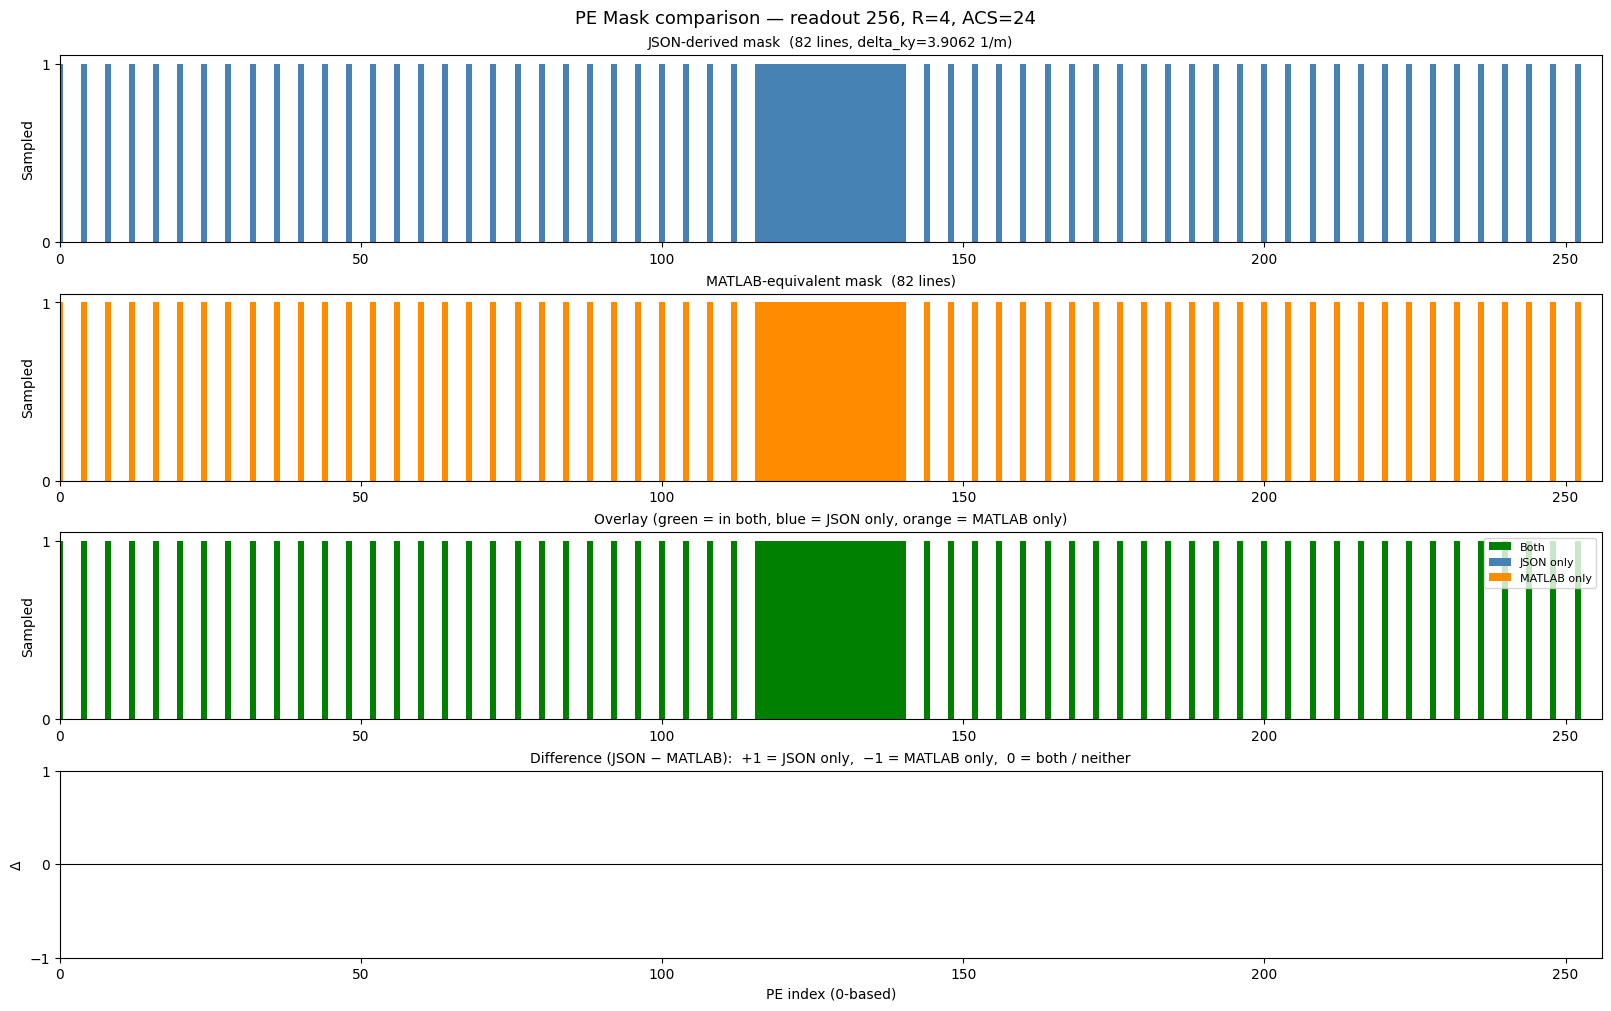

Figure saved to pe_mask_comparison.png


In [18]:
fig, axes = plt.subplots(4, 1, figsize=(16, 10), constrained_layout=True)
fig.suptitle(
    f"PE Mask comparison — readout {READOUT_LENGTH}, R={R_FACTOR}, ACS={ACS_LINES}",
    fontsize=13,
)

idx_axis = np.arange(READOUT_LENGTH)

# ── Row 0: JSON mask ──────────────────────────────────────────────────────────
axes[0].bar(idx_axis, json_mask.astype(int), width=1.0, color="steelblue")
axes[0].set_title(f"JSON-derived mask  ({json_mask.sum()} lines, delta_ky={delta_ky:.4f} 1/m)",
                  fontsize=10)
axes[0].set_ylabel("Sampled")
axes[0].set_xlim(0, READOUT_LENGTH)
axes[0].set_yticks([0, 1])

# ── Row 1: MATLAB-equiv mask ──────────────────────────────────────────────────
axes[1].bar(idx_axis, matlab_mask.astype(int), width=1.0, color="darkorange")
axes[1].set_title(f"MATLAB-equivalent mask  ({matlab_mask.sum()} lines)",
                  fontsize=10)
axes[1].set_ylabel("Sampled")
axes[1].set_xlim(0, READOUT_LENGTH)
axes[1].set_yticks([0, 1])

# ── Row 2: Overlay comparison ─────────────────────────────────────────────────
both_val   = (json_mask & matlab_mask).astype(float)
only_json  = (json_mask & ~matlab_mask).astype(float)
only_mlab  = (~json_mask & matlab_mask).astype(float)

axes[2].bar(idx_axis, both_val,  width=1.0, color="green",      label="Both")
axes[2].bar(idx_axis, only_json, width=1.0, color="steelblue",  label="JSON only")
axes[2].bar(idx_axis, only_mlab, width=1.0, color="darkorange", label="MATLAB only")
axes[2].set_title("Overlay (green = in both, blue = JSON only, orange = MATLAB only)",
                  fontsize=10)
axes[2].set_ylabel("Sampled")
axes[2].set_xlim(0, READOUT_LENGTH)
axes[2].set_yticks([0, 1])
axes[2].legend(loc="upper right", fontsize=8)

# ── Row 3: Difference (JSON - MATLAB), zoomed around center ACS ───────────────
diff = json_mask.astype(int) - matlab_mask.astype(int)
axes[3].bar(idx_axis, diff, width=1.0, color=[
    "steelblue" if d > 0 else ("darkorange" if d < 0 else "lightgray")
    for d in diff
])
axes[3].axhline(0, color="black", linewidth=0.8)
axes[3].set_title("Difference (JSON − MATLAB):  +1 = JSON only,  −1 = MATLAB only,  0 = both / neither",
                  fontsize=10)
axes[3].set_xlabel("PE index (0-based)")
axes[3].set_ylabel("Δ")
axes[3].set_xlim(0, READOUT_LENGTH)
axes[3].set_yticks([-1, 0, 1])

plt.savefig("pe_mask_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved to pe_mask_comparison.png")

## 7 — Zoom into the ACS region

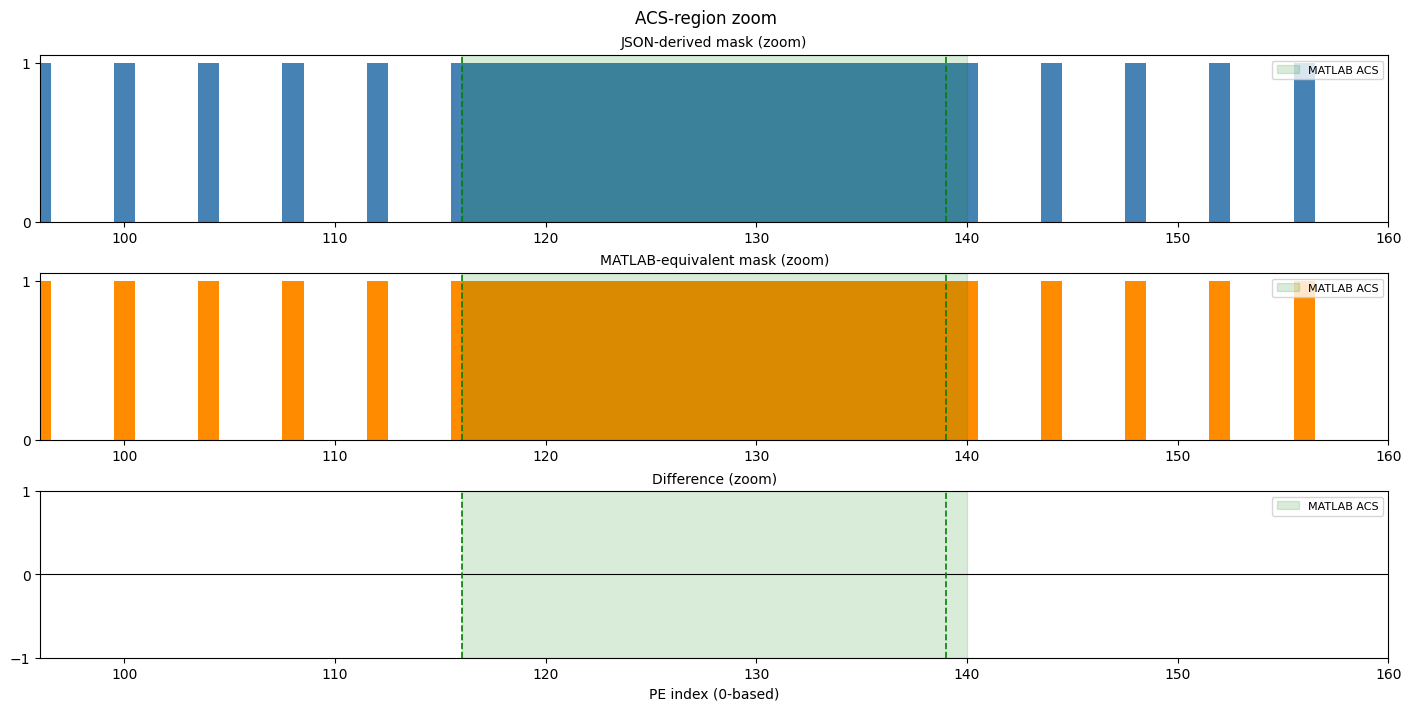

Zoom figure saved to pe_mask_comparison_zoom.png


In [19]:
# Window that shows ±20 lines around the theoretical ACS block
pad   = 20
lo    = max(0, acs_start - pad)
hi    = min(READOUT_LENGTH, acs_end + pad)
zoom  = np.arange(lo, hi)

fig2, axes2 = plt.subplots(3, 1, figsize=(14, 7), constrained_layout=True)
fig2.suptitle("ACS-region zoom", fontsize=12)

axes2[0].bar(zoom, json_mask[zo := slice(lo, hi)].astype(int),
             width=1.0, color="steelblue")
axes2[0].set_title("JSON-derived mask (zoom)", fontsize=10)
axes2[0].axvspan(acs_start, acs_end, alpha=0.15, color="green", label="MATLAB ACS")
axes2[0].set_yticks([0, 1]);  axes2[0].set_xlim(lo, hi)
axes2[0].legend(fontsize=8)

axes2[1].bar(zoom, matlab_mask[zo].astype(int),
             width=1.0, color="darkorange")
axes2[1].set_title("MATLAB-equivalent mask (zoom)", fontsize=10)
axes2[1].axvspan(acs_start, acs_end, alpha=0.15, color="green", label="MATLAB ACS")
axes2[1].set_yticks([0, 1]);  axes2[1].set_xlim(lo, hi)
axes2[1].legend(fontsize=8)

axes2[2].bar(zoom, diff[zo], width=1.0, color=[
    "steelblue" if d > 0 else ("darkorange" if d < 0 else "lightgray")
    for d in diff[zo]
])
axes2[2].axhline(0, color="black", linewidth=0.8)
axes2[2].axvspan(acs_start, acs_end, alpha=0.15, color="green", label="MATLAB ACS")
axes2[2].set_title("Difference (zoom)", fontsize=10)
axes2[2].set_xlabel("PE index (0-based)")
axes2[2].set_yticks([-1, 0, 1]);  axes2[2].set_xlim(lo, hi)
axes2[2].legend(fontsize=8)

# Annotate exact boundary lines
for ax in axes2:
    ax.axvline(acs_start, color="green",  linewidth=1.2, linestyle="--")
    ax.axvline(acs_end - 1, color="green", linewidth=1.2, linestyle="--")

plt.savefig("pe_mask_comparison_zoom.png", dpi=150, bbox_inches="tight")
plt.show()
print("Zoom figure saved to pe_mask_comparison_zoom.png")

## 8 — ACS auto-detection sanity check

This replicates the ACS-detection logic used in `reconstruct_equispaced` so you can verify  
the detected `[acs_start, acs_end)` matches what MATLAB intended.

In [20]:
# ── ACS detection from JSON mask (mirrors equispaced_recon.py) ───────────────
diffs_between  = np.diff(json_pe_idx)
dense_positions = np.where(diffs_between == 1)[0]

if dense_positions.size > 0:
    json_acs_start = int(json_pe_idx[dense_positions[0]])
    json_acs_end   = int(json_pe_idx[dense_positions[-1]]) + 2  # exclusive
    json_acs_lines = json_acs_end - json_acs_start
    print(f"JSON-mask ACS (auto-detected) : [{json_acs_start}, {json_acs_end})  "
          f"→ {json_acs_lines} lines")
else:
    print("WARNING: No consecutive step-1 block found in JSON mask — ACS not detected.")
    json_acs_start = json_acs_end = None

print(f"MATLAB-equiv ACS (theoretical): [{acs_start}, {acs_end})  "
      f"→ {acs_end - acs_start} lines")

if json_acs_start is not None:
    start_diff = json_acs_start - acs_start
    end_diff   = json_acs_end   - acs_end
    print()
    print(f"ACS start offset (JSON − MATLAB) : {start_diff:+d}")
    print(f"ACS end   offset (JSON − MATLAB) : {end_diff:+d}")
    if start_diff == end_diff:
        print(f"→ Consistent with a global PE-line shift of {start_diff:+d}.")
    else:
        print("→ Start and end offsets differ — check boundary lines carefully.")

JSON-mask ACS (auto-detected) : [116, 141)  → 25 lines
MATLAB-equiv ACS (theoretical): [116, 140)  → 24 lines

ACS start offset (JSON − MATLAB) : +0
ACS end   offset (JSON − MATLAB) : +1
→ Start and end offsets differ — check boundary lines carefully.


## 9 — Raw ky values around the ACS region

Print the actual ky values from the JSON in the ACS neighbourhood so you can  
cross-check manually with the MATLAB output.

In [21]:
traj    = load_trajectory_local(str(JSON_PATH))
ky_vals = traj[:, 1]
unique_ky = np.sort(np.unique(ky_vals))

print(f"Total unique ky values  : {len(unique_ky)}")
print(f"ky range                : [{unique_ky[0]:.4f}, {unique_ky[-1]:.4f}]  1/m")
print(f"delta_ky (min spacing)  : {delta_ky:.6f}  1/m")
print()

# Round ky values to PE indices and show ACS neighbourhood
n = READOUT_LENGTH
pe_from_ky = np.round(unique_ky / delta_ky + n / 2).astype(int)

# Find the dense block in pe_from_ky
center_region_mask = (pe_from_ky >= acs_start - 5) & (pe_from_ky <= acs_end + 5)

print("ky → PE index table (ACS neighbourhood ± 5 lines):")
print(f"{'ky (1/m)':>14}  {'PE index':>8}  {'In JSON?':>8}  {'In MATLAB?':>10}  {'Step':>6}")
print("-" * 58)
prev_pe = None
for ky_v, pe_v in zip(unique_ky[center_region_mask], pe_from_ky[center_region_mask]):
    step_str = f"+{pe_v - prev_pe}" if prev_pe is not None else "—"
    in_json   = "✓" if pe_v in json_set   else "✗"
    in_matlab = "✓" if pe_v in matlab_set else "✗"
    print(f"  {ky_v:>12.4f}  {pe_v:>8d}  {in_json:>8}  {in_matlab:>10}  {step_str:>6}")
    prev_pe = pe_v

Total unique ky values  : 82
ky range                : [-490.4726, 493.9024]  1/m
delta_ky (min spacing)  : 3.906250  1/m

ky → PE index table (ACS neighbourhood ± 5 lines):
      ky (1/m)  PE index  In JSON?  In MATLAB?    Step
----------------------------------------------------------
      -52.9726       114         ✗           ✗       —
      -49.0663       115         ✗           ✗      +1
      -45.1601       116         ✓           ✓      +1
      -41.2538       117         ✓           ✓      +1
      -37.3476       118         ✓           ✓      +1
      -33.4413       119         ✓           ✓      +1
      -29.5351       120         ✓           ✓      +1
      -25.6288       121         ✓           ✓      +1
      -21.7226       122         ✓           ✓      +1
      -17.8163       123         ✓           ✓      +1
      -13.9101       124         ✓           ✓      +1
      -10.0038       125         ✓           ✓      +1
       -6.0976       126         ✓           ✓      